# Pipeline de ingesta y consumo eléctrico por central

Este notebook explica, paso a paso y con los datos reales, qué hace `src/energy_dispatch/data/ingestion.py` y por qué. Cada sección corresponde a una función del módulo y la ejecuta tal cual, importándola del paquete.

| Paso | Función | Qué resuelve |
|---|---|---|
| 0 | `proyectar_historico_excel` | Consumo mensual de la isla para 2025-2026 a partir del histórico oficial |
| 1 | `cargar_y_unificar_origen` | Lecturas limpias + estaciones en un único DataFrame, con tipos y zona horaria homogéneos |
| 2 | `ordenar_y_limpiar_duplicados` | Orden cronológico y eliminación de marcas de tiempo repetidas |
| 3 | `auditar_frecuencia_y_huecos` | Comprobar que la serie es regular (cada 5 min) y localizar huecos |
| 4 | `extrapolar_consumo_centrales` | Estimar `consumo_kw` por central y el total de la isla |
| — | `ejecutar_pipeline_ingesta` | Orquestar todo y guardar el resultado en `data/interim/` |

> **Por qué hay que extrapolar el consumo:** las lecturas del proyecto son meteorológicas (temperatura, humedad, viento…) y no incluyen consumo eléctrico. Tampoco existe un dato público de carga horaria de Aruba. Lo que sí es público es el **consumo mensual por grupo tarifario** (CBS Aruba, Tabla 3.8). El módulo reparte esa energía mensual entre centrales y a lo largo del día, modulándola con el clima real.

## Preparación

Importamos el módulo del paquete para ejecutar exactamente el mismo código que el pipeline.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path('..').resolve() / 'src'))
from energy_dispatch.data import ingestion as ing

AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#8a8a85'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
    'axes.edgecolor': GRIS, 'axes.labelcolor': '#3d3d3a', 'xtick.color': '#3d3d3a', 'ytick.color': '#3d3d3a',
})

RAIZ = Path('..').resolve()
LECTURAS = RAIZ / 'data' / 'processed' / '0_cleaning' / 'aruba_readings_cleaned.json'
ESTACIONES = RAIZ / 'data' / 'raw' / 'aruba_stations.json'

## 0. Proyección del consumo mensual (`proyectar_historico_excel`)

El Excel del CBS (*Table 3.8 – Energy consumption per month in kWh by tariff group 2015-2024*) trae un bloque de 20 filas por año. La función:

1. Lee los bloques de **2024, 2023, 2022 y 2021** (filas 0, 20, 40 y 60). Se usan solo años post-pandemia porque 2020 tuvo una caída de turismo excepcional que distorsionaría la tendencia.
2. De cada bloque toma los 12 meses (filas `r+3` a `r+14`) y la columna 8, que es el **total de todos los grupos tarifarios**.
3. Para **cada mes por separado** ajusta una recta (`scipy.stats.linregress`) consumo-vs-año y la evalúa en 2025 y 2026.

Ajustar mes a mes, en vez de una única recta anual, conserva la **estacionalidad**: cada mes tiene su propio nivel (más calor, más turismo) y su propia tendencia.

El resultado es un diccionario `{(año, mes): MWh}`. Si el Excel no está, en la sección 4 el código usa 85 000 MWh/mes para cualquier mes que falte en el diccionario.

In [2]:
excels = sorted((RAIZ / 'data' / 'external').glob('Table-3.8-*.xlsx'))
if excels:
    monthly_proj = ing.proyectar_historico_excel(excels[0])
    proy = pd.Series(monthly_proj).rename_axis(['año', 'mes']).unstack(0).round(0)
    display(proy)
else:
    monthly_proj = {}
    print('Excel del CBS no encontrado en data/external/: se usará el valor por defecto de 85 000 MWh/mes.')

Excel del CBS no encontrado en data/external/: se usará el valor por defecto de 85 000 MWh/mes.


## 1. Carga y unificación (`cargar_y_unificar_origen`)

- Lee el JSON de lecturas limpias del paso 0 y el de estaciones.
- **Convierte `timestamp` a UTC** (`utc=True`): todas las marcas de tiempo quedan en una única zona horaria, así se pueden comparar y ordenar sin ambigüedad. `errors='coerce'` convierte fechas mal formadas en `NaT` en vez de romper la carga (se eliminan en el paso 2).
- Une cada lectura con los datos de su estación (`station_id` ↔ `id`): nombre, latitud, longitud, elevación.
- **Fuerza los tipos numéricos** a `float64`: si el JSON trae algún valor como texto, se convierte o pasa a `NaN`, y las operaciones posteriores no fallan.
- `uv_index` es un índice entero por definición: se redondea y se guarda como `int64` (los nulos pasan a 0).

In [3]:
df = ing.cargar_y_unificar_origen(LECTURAS, ESTACIONES)
print(df.shape)
df.dtypes

2026-10-20 15:41:28,248 - [INFO] - Leyendo mediciones desde: aruba_readings_20260924.json


(1351008, 18)


id                                    str
station_id                            str
timestamp             datetime64[us, UTC]
temperature_c                     float64
humidity_pct                      float64
wind_speed_kmh                    float64
wind_direction_deg                float64
pressure_hpa                      float64
precipitation_mm                  float64
visibility_km                     float64
uv_index                            int64
name                                  str
code                                  str
latitude                          float64
longitude                         float64
elevation_m                       float64
district                              str
is_active                            bool
dtype: object

## 2. Orden y duplicados (`ordenar_y_limpiar_duplicados`)

- Elimina filas sin `timestamp` válido.
- **Ordena por central y tiempo.** Todo lo que viene después (diferencias entre lecturas, *lags*, medias móviles) asume que las filas de cada central están en orden cronológico.
- **Elimina duplicados** de `(station_id, timestamp)` quedándose con el primero. Dos lecturas de la misma central en el mismo instante no pueden ser ambas ciertas, y además duplicarían el peso de ese instante en el entrenamiento y romperían los *lags* (desplazar *k* filas ya no equivaldría a *k* × 5 min).

In [4]:
df = ing.ordenar_y_limpiar_duplicados(df)

2026-10-20 15:41:37,230 - [WARNING] - Detectadas y eliminadas 82944 lecturas con timestamp repetido.


2026-10-20 15:41:37,562 - [INFO] - Total registros válidos ordenados: 1,268,064 (de 1,351,008).


## 3. Frecuencia y huecos (`auditar_frecuencia_y_huecos`)

Las estaciones deberían enviar una lectura cada **5 minutos**. La función calcula, por central, el tiempo entre cada lectura y la anterior (`groupby('station_id')['timestamp'].diff()`) y marca como hueco cualquier salto mayor de 5 min. Muestra cuántos hay por central y el más largo.

No rellena ni borra nada: es una **auditoría**. Sirve para saber si se puede confiar en que la serie es regular antes de construir variables que dependen de ello.

In [5]:
df = ing.auditar_frecuencia_y_huecos(df, freq='5min')

2026-10-20 15:41:37,585 - [INFO] - Auditando frecuencia de muestreo (5min) en las 12 centrales...


2026-10-20 15:41:37,659 - [WARNING] - Se localizaron 36 huecos temporales mayores a 5min.


2026-10-20 15:41:37,664 - [INFO] - Resumen de huecos por central:
                       count             max
name                                        
Alto Vista                 3 7 days 00:05:00
Arikok National Park       3 7 days 00:05:00
Hooiberg Summit            3 7 days 00:05:00
Malmok                     3 7 days 00:05:00
Noord                      3 7 days 00:05:00
Oranjestad Central         3 7 days 00:05:00
Palm Beach                 3 7 days 00:05:00
Paradera                   3 7 days 00:05:00
Queen Beatrix Airport      3 7 days 00:05:00
San Nicolaas               3 7 days 00:05:00
Santa Cruz                 3 7 days 00:05:00
Savaneta                   3 7 days 00:05:00


Detalle de los huecos: en qué instante se reanudan las lecturas y cuánto tiempo faltaba. Las 12 centrales tienen los mismos huecos a la vez, así que son cortes del sistema de adquisición y no fallos de una estación concreta.

In [6]:
salto = df.groupby('station_id')['timestamp'].diff()
huecos = df.loc[salto > pd.Timedelta('5min'), ['timestamp']].assign(duracion=salto[salto > pd.Timedelta('5min')])
huecos.groupby(['timestamp', 'duracion']).size().rename('centrales afectadas').reset_index()

,timestamp,duracion,centrales afectadas
0,2026-01-11 00:00:00+00:00,7 days 00:05:00,12
1,2026-03-31 22:00:00+00:00,1 days 00:05:00,12
2,2026-05-25 00:00:00+00:00,7 days 00:05:00,12


Las semanas sin lecturas **no se rellenan**: el consumo se calcula a partir del clima de cada lectura, así que en esos periodos tampoco habrá consumo. Cualquier variable que mire hacia atrás en el tiempo (*lags*, medias móviles) debe comprobar que el dato anterior existe y no tomar uno de antes del hueco.

## 4. Extrapolación del consumo (`extrapolar_consumo_centrales`)

Para cada central $s$ e instante $t$:

$$
\text{consumo}_{s,t} = \underbrace{\frac{E_{\text{mes}} \cdot 1000}{\text{días}_{\text{mes}} \cdot 24}}_{\text{kW medios de la isla}} \cdot \underbrace{c_s}_{\text{cuota}} \cdot \underbrace{f_{\text{día}}(h)}_{\text{curva diaria}} \cdot \underbrace{f_{\text{clima}}(T, HR, v)}_{\text{meteorología}} \; + \; \underbrace{\varepsilon_{s,t}}_{\text{ruido}}
$$

Vamos factor a factor.

### 4.1 Potencia media de la isla

La energía mensual (MWh) se pasa a **potencia media** (kW) dividiendo por las horas del mes: $\text{MWh} \cdot 1000 / (\text{días} \cdot 24)$. Por ejemplo, 85 000 MWh en un mes de 30 días son ≈ 118 000 kW (118 MW) de media.

In [7]:
for dias in (28, 30, 31):
    print(f'85 000 MWh en un mes de {dias} días -> {85000 * 1000 / (dias * 24):,.0f} kW medios')

85 000 MWh en un mes de 28 días -> 126,488 kW medios
85 000 MWh en un mes de 30 días -> 118,056 kW medios
85 000 MWh en un mes de 31 días -> 114,247 kW medios


### 4.2 Cuota de cada central (`STATION_SHARES`)

La potencia de la isla se reparte entre las 12 centrales según el peso de cada zona en los grupos tarifarios: la zona hotelera de Palm Beach y la capital (Oranjestad) concentran más consumo; zonas rurales como Arikok, muy poco. Las cuotas suman 1, así que la suma de las centrales reproduce el total de la isla.

In [8]:
nombres = df.drop_duplicates('station_id').set_index('station_id')['name']
cuotas = pd.Series(ing.STATION_SHARES, name='cuota').to_frame()
cuotas.insert(0, 'estación', cuotas.index.map(nombres))
print('Suma de cuotas:', round(cuotas['cuota'].sum(), 3))
cuotas.reset_index(drop=True)

Suma de cuotas: 1.0


,estación,cuota
0,Palm Beach,0.160
1,Oranjestad Central,0.145
2,Noord,0.115
3,Queen Beatrix Airport,0.105
4,San Nicolaas,0.095
5,Malmok,0.080
6,Santa Cruz,0.075
7,Paradera,0.065
8,Savaneta,0.060
9,Alto Vista,0.045


### 4.3 Curva diaria

El consumo no es igual a todas horas. La curva es:

$$
f_{\text{día}}(h) = \frac{0.78 + 0.32\,\sin^2\!\left(\frac{(h-7)}{24}\,2\pi\right) + 0.12\,e^{-(h-14.5)^2/10}}{\text{media de la curva en el día}}
$$

- **0.78:** carga base, lo que se consume siempre (hoteles, alumbrado, desalación).
- **Término $\sin^2$:** oscilación a lo largo del día.
- **Término gaussiano centrado en 14.5 h:** un abultamiento a primera hora de la tarde.
- **División por la media** (calculada sobre una rejilla de 288 puntos = un día cada 5 min): la curva tiene media 1, así que **reparte la energía del día sin cambiar el total mensual del Excel**.

`h` es la hora del `timestamp`, que está en **UTC** (paso 1). Aruba está en UTC−4, así que dibujamos la curva con las dos escalas:

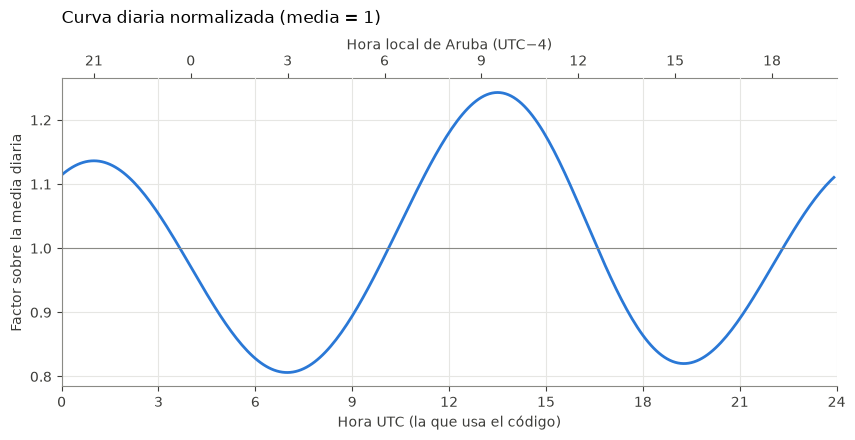

media 1.000 | mín 0.81 a las 7.0 UTC | máx 1.24 a las 13.5 UTC | pico/media 1.24


In [9]:
h = np.linspace(0, 24, 288, endpoint=False)
raw = 0.78 + 0.32 * np.sin((h - 7) / 24 * 2 * np.pi) ** 2 + 0.12 * np.exp(-((h - 14.5) ** 2) / 10)
curva = raw / raw.mean()

fig, ax = plt.subplots()
ax.plot(h, curva, color=AZUL)
ax.axhline(1, color=GRIS, linewidth=0.8)
ax.set(xlabel='Hora UTC (la que usa el código)', ylabel='Factor sobre la media diaria', xticks=range(0, 25, 3), xlim=(0, 24))
sec = ax.secondary_xaxis('top', functions=(lambda x: x - 4, lambda x: x + 4))
sec.set_xlabel('Hora local de Aruba (UTC−4)')
sec.set_xticks(range(-3, 21, 3), [str(v % 24) for v in range(-3, 21, 3)])
ax.set_title('Curva diaria normalizada (media = 1)', loc='left', pad=40)
plt.show()

print(f'media {curva.mean():.3f} | mín {curva.min():.2f} a las {h[curva.argmin()]:.1f} UTC | '
      f'máx {curva.max():.2f} a las {h[curva.argmax()]:.1f} UTC | pico/media {curva.max():.2f}')

### 4.4 Modulación meteorológica

$$
f_{\text{clima}} = 1 + 0.035\,(T - 28.5) + 0.002\,(HR - 74) - 0.003\,(v - 22), \qquad f_{\text{clima}} \in [0.75,\ 1.35]
$$

- **Temperatura (+3.5 % por °C sobre 28.5 °C):** es el término dominante. En Aruba la mayor parte de la carga variable es aire acondicionado, que trabaja más cuanto más calor hace.
- **Humedad (+0.2 % por punto sobre 74 %):** con más humedad los equipos de climatización tienen que quitar también calor latente.
- **Viento (−0.3 % por km/h sobre 22 km/h):** el alisio refresca y reduce ligeramente la necesidad de climatizar.
- Los valores de referencia (28.5 °C, 74 %, 22 km/h) son condiciones típicas de la isla: con ellas el factor vale 1.
- **`np.clip` a [0.75, 1.35]:** evita que una lectura extrema (o errónea) dispare o hunda el consumo.

Comparamos las referencias con las medias reales de las lecturas y vemos la distribución del factor:

                  referencia en la fórmula  media de las lecturas
temperatura (°C)                      28.5                   28.3
humedad (%)                           74.0                   77.0
viento (km/h)                         22.0                   23.9

factor clima -> media 0.993 | p1 0.802 | p99 1.158 | recortado 0.05%


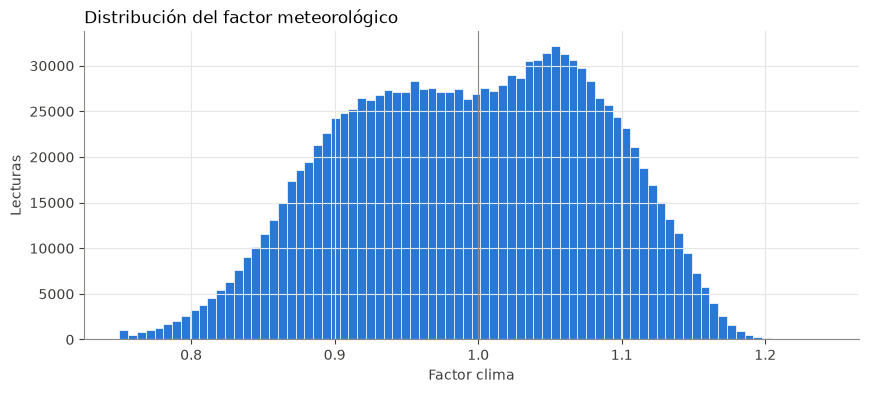

In [10]:
print(pd.DataFrame({
    'referencia en la fórmula': [28.5, 74.0, 22.0],
    'media de las lecturas': df[['temperature_c', 'humidity_pct', 'wind_speed_kmh']].mean().round(1).to_numpy(),
}, index=['temperatura (°C)', 'humedad (%)', 'viento (km/h)']))

factor = np.clip(1 + 0.035 * (df['temperature_c'] - 28.5) + 0.002 * (df['humidity_pct'] - 74)
                 - 0.003 * (df['wind_speed_kmh'] - 22), 0.75, 1.35)
print(f"\nfactor clima -> media {factor.mean():.3f} | p1 {factor.quantile(.01):.3f} | p99 {factor.quantile(.99):.3f} | "
      f"recortado {((factor == 0.75) | (factor == 1.35)).mean():.2%}")

fig, ax = plt.subplots()
ax.hist(factor, bins=80, color=AZUL, edgecolor='white', linewidth=0.5)
ax.axvline(1, color=GRIS, linewidth=0.8)
ax.set(xlabel='Factor clima', ylabel='Lecturas')
ax.set_title('Distribución del factor meteorológico', loc='left')
plt.show()

### 4.5 Ruido

Se suma un ruido normal con desviación típica del **0.8 % de la potencia base de cada central** (`np.random.normal(0, base_station_kw * 0.008)`). Representa la variabilidad que no explican ni la hora ni el clima, y evita que la serie sea una función perfectamente determinista de las variables de entrada. Al ser proporcional a la base, las centrales grandes tienen más ruido absoluto que las pequeñas. `np.random.seed(42)` hace que el resultado sea **reproducible**: cada ejecución genera exactamente la misma serie.

### 4.6 Total de la isla

`consumo_isla_total_kw` suma el consumo de las 12 centrales en cada instante (`groupby('timestamp').transform('sum')`), así cada fila lleva también el total insular sincronizado.

Ejecutamos la función:

In [11]:
df = ing.extrapolar_consumo_centrales(df, monthly_proj)
df[['station_id', 'name', 'timestamp', 'temperature_c', 'consumo_kw', 'consumo_isla_total_kw']].head()

2026-10-20 15:41:38,290 - [INFO] - Extrapolando consumo eléctrico por central a partir de histórico y clima...


2026-10-20 15:41:39,027 - [INFO] - Consumo por central (kW) -> Media: 9,688.16 kW | Mín: 1,786.33 kW | Máx: 26,258.50 kW


2026-10-20 15:41:39,030 - [INFO] - Consumo Total Isla (suma 12 centrales) -> Media: 116,257.88 kW


,station_id,name,timestamp,temperature_c,consumo_kw,consumo_isla_total_kw
0,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,Noord,2025-09-01 00:00:00+00:00,32.4,17041.22,144842.13
1,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,Noord,2025-09-01 00:05:00+00:00,32.4,17025.13,145468.76
2,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,Noord,2025-09-01 00:10:00+00:00,32.6,17264.12,146815.90
3,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,Noord,2025-09-01 00:15:00+00:00,32.6,17400.70,146885.15
4,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,Noord,2025-09-01 00:20:00+00:00,32.8,17366.15,147445.21


## 5. Resultado

Total isla -> media 116.3 MW | mín 83.6 MW | máx 157.6 MW | pico/media 1.355


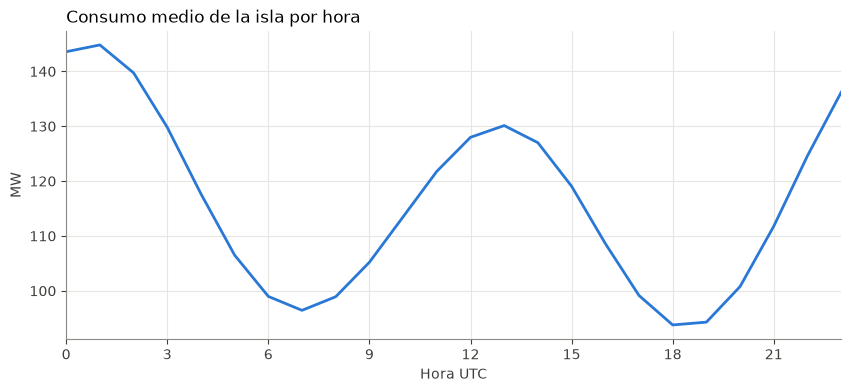

In [12]:
isla = (df.drop_duplicates('timestamp').set_index('timestamp')['consumo_isla_total_kw'] / 1000).rename('MW')
print(f'Total isla -> media {isla.mean():.1f} MW | mín {isla.min():.1f} MW | máx {isla.max():.1f} MW | pico/media {isla.max() / isla.mean():.3f}')

perfil = isla.groupby(isla.index.hour).mean()
fig, ax = plt.subplots()
ax.plot(perfil.index, perfil, color=AZUL)
ax.set(xlabel='Hora UTC', ylabel='MW', xticks=range(0, 24, 3), xlim=(0, 23))
ax.set_title('Consumo medio de la isla por hora', loc='left')
plt.show()

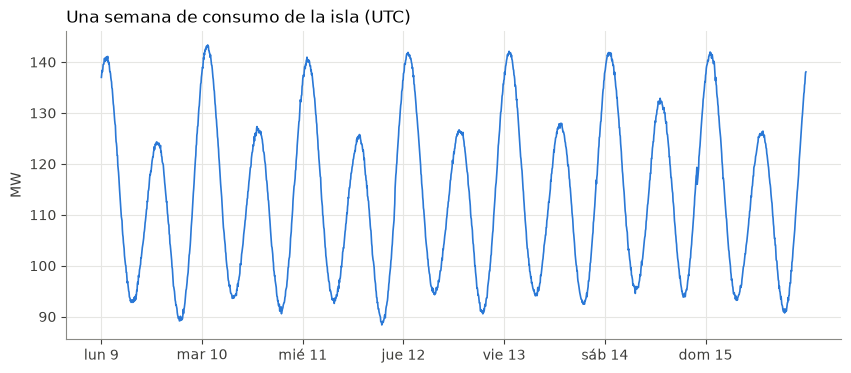

In [13]:
semana = isla.loc['2026-03-09':'2026-03-15']
fig, ax = plt.subplots()
ax.plot(semana.index, semana, color=AZUL, linewidth=1.2)
dias = pd.date_range('2026-03-09', periods=7, freq='D', tz='UTC')
ax.set_xticks(dias, [f"{n} {d.day}" for n, d in zip(['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom'], dias)])
ax.set(ylabel='MW')
ax.set_title('Una semana de consumo de la isla (UTC)', loc='left')
plt.show()

In [14]:
por_central = df.groupby('name')['consumo_kw'].agg(['mean', 'min', 'max']).div(1000).round(2)
por_central.columns = ['media (MW)', 'mín (MW)', 'máx (MW)']
por_central.sort_values('media (MW)', ascending=False)

,media (MW),mín (MW),máx (MW)
name,,,
Palm Beach,18.78,12.60,26.26
Oranjestad Central,16.96,11.26,23.77
Noord,13.43,8.88,18.71
Queen Beatrix Airport,12.20,8.17,16.80
San Nicolaas,11.03,7.51,15.37
Malmok,9.36,5.89,13.22
Santa Cruz,8.63,5.63,12.06
Paradera,7.54,5.00,10.45
Savaneta,6.99,4.47,9.66


## 6. Orquestación y salidas (`ejecutar_pipeline_ingesta`)

Esta función encadena todo lo anterior (Excel → carga → duplicados → auditoría → consumo) y la lanza `scripts/run_ingestion.py`. Aquí no se ejecuta porque escribe ficheros en disco y necesita el Excel del CBS.

- **Rutas candidatas:** para cada fichero de entrada prueba varias ubicaciones (`data/raw/`, `aruba_lecturas/`, la raíz…) y usa la primera que exista. Así el script funciona aunque cada miembro del equipo tenga los datos en una carpeta distinta. `Path(...).resolve()` normaliza la ruta para que funcione igual en Windows y en Linux.
- **Salidas en `data/interim/`** (se crea si no existe):
  - `aruba_base_limpio.csv`: el DataFrame completo, con todas las columnas, incluidas las de la estación y `consumo_isla_total_kw`.
  - `aruba_readings_con_consumo.json`: el mismo formato que el JSON de lecturas original más la columna `consumo_kw`, para que cualquier código que ya leyera las lecturas pueda leer también el consumo sin cambios.

## 7. Generación eólica esperada (Parque Vader Piet)

El viento es la principal fuente renovable de Aruba: el **Parque Eólico Vader Piet** tiene **10 aerogeneradores Vestas V90-3.0 MW** (30 MW en total). Con la ficha técnica del fabricante (`docs/ProductbrochureV90_3_0_UK.pdf`) y el viento real de las estaciones se puede estimar cuánta energía genera en cada instante.

| Dato del folleto | Valor | Uso |
|---|---|---|
| Potencia nominal | 3 000 kW | Techo de la curva |
| Velocidad de arranque (*cut-in*) | 4 m/s | Por debajo, potencia 0 |
| Velocidad nominal | 15 m/s | A partir de aquí, 3 000 kW |
| Velocidad de corte (*cut-out*) | 25 m/s | La turbina se para por protección |
| Altura de buje | 80 m (o 105 m) | Altura a la que hay que llevar el viento medido |
| Curva de potencia | gráfica | Digitalizada punto a punto (cada 0.5 m/s) |

El cálculo tiene cuatro pasos: **viento en el parque → viento a 80 m → corrección por densidad del aire → curva de potencia × 10 turbinas × pérdidas**.

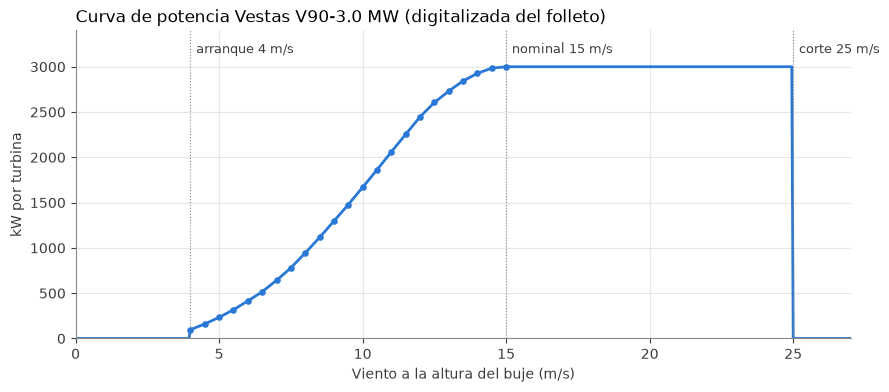

In [15]:
# Curva de potencia V90-3.0 MW digitalizada de la gráfica del folleto (densidad estándar 1.225 kg/m3)
CURVA_V_MS = np.array([0.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0,
                       10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 15.0, 25.0])
CURVA_KW = np.array([0, 40, 97, 160, 233, 317, 414, 516, 641, 780, 944, 1115, 1296, 1478, 1668,
                     1862, 2061, 2254, 2447, 2606, 2732, 2843, 2928, 2984, 3000, 3000], dtype=float)

POTENCIA_NOMINAL_KW = 3000.0
VIENTO_ARRANQUE_MS, VIENTO_CORTE_MS = 4.0, 25.0
ALTURA_BUJE_M = 80.0
N_TURBINAS = 10
DENSIDAD_REFERENCIA = 1.225   # kg/m3
ALTURA_SENSOR_M = 10.0        # altura estándar (OMM) de los anemómetros de las estaciones
ALFA_CIZALLADURA = 0.14       # perfil de viento en terreno abierto / costero (~1/7)
FACTOR_PERDIDAS = 0.90        # disponibilidad 97 % x estelas entre turbinas 95 % x pérdidas eléctricas 98 %

fig, ax = plt.subplots()
v = np.linspace(0, 27, 541)
p = np.where((v < VIENTO_ARRANQUE_MS) | (v >= VIENTO_CORTE_MS), 0, np.interp(v, CURVA_V_MS, CURVA_KW))
ax.plot(v, p, color=AZUL)
en_ficha = (CURVA_V_MS >= VIENTO_ARRANQUE_MS) & (CURVA_V_MS < VIENTO_CORTE_MS)
ax.scatter(CURVA_V_MS[en_ficha], CURVA_KW[en_ficha], s=14, color=AZUL, zorder=3)
for x, txt in [(VIENTO_ARRANQUE_MS, 'arranque 4 m/s'), (15, 'nominal 15 m/s'), (VIENTO_CORTE_MS, 'corte 25 m/s')]:
    ax.axvline(x, color=GRIS, linewidth=0.8, linestyle=':')
    ax.text(x + 0.2, 3150, txt, color='#3d3d3a', fontsize=9)
ax.set(xlabel='Viento a la altura del buje (m/s)', ylabel='kW por turbina', xlim=(0, 27), ylim=(0, 3400))
ax.set_title('Curva de potencia Vestas V90-3.0 MW (digitalizada del folleto)', loc='left')
plt.show()

### 7.1 Viento en el parque

Ninguna estación está en el propio parque. Se usan las **3 estaciones más cercanas** a Vader Piet (calculadas en `1_filter_stations.ipynb`) y se promedian **ponderando por 1 / distancia**: la más cercana pesa más. Lo mismo para temperatura, humedad y presión, que hacen falta para la densidad del aire.

In [16]:
cercanas = pd.read_json(RAIZ / 'data' / 'processed' / '1_station_filtering' / 'aruba_stations_ordered_by_distance_m.json')
display(cercanas[['name', 'elevation_m', 'distance_m']].round(0))

pesos = 1.0 / cercanas.set_index('id')['distance_m']
lect = df[df['station_id'].isin(pesos.index)].copy()
lect['peso'] = lect['station_id'].map(pesos)
lect['wind_speed_ms'] = lect['wind_speed_kmh'] / 3.6

cols = ['wind_speed_ms', 'temperature_c', 'humidity_pct', 'pressure_hpa']
sumas = lect[cols].mul(lect['peso'], axis=0).assign(peso=lect['peso']).groupby(lect['timestamp']).sum()
parque = sumas[cols].div(sumas['peso'], axis=0)
parque.describe().round(2)

,name,elevation_m,distance_m
0,San Nicolaas,8,4588.0
1,Savaneta,4,6747.0
2,Arikok National Park,120,7393.0


,wind_speed_ms,temperature_c,humidity_pct,pressure_hpa
count,105672.00,105672.00,105672.00,105672.00
mean,6.64,28.19,77.16,1014.36
std,0.66,2.74,6.74,1.18
min,5.00,21.29,65.14,1006.28
25%,6.11,25.93,71.09,1013.31
50%,6.64,28.24,77.30,1014.25
75%,7.19,30.46,82.03,1015.49
max,10.45,33.86,95.99,1016.55


### 7.2 Viento a la altura del buje

Los anemómetros miden a ~10 m, pero el rotor está a 80 m, donde sopla más fuerte (el suelo frena el viento). Se usa la **ley potencial** del perfil de viento:

$$
v_{80} = v_{10} \cdot \left(\frac{80}{10}\right)^{\alpha}, \qquad \alpha = 0.14 \;\Rightarrow\; v_{80} \approx 1.34\, v_{10}
$$

Comprobación de coherencia con los umbrales de seguridad: el corte de 25 m/s a 80 m equivale a 25 / 1.34 ≈ 18.7 m/s ≈ **67 km/h a 10 m**, que es justo el umbral de *cut-out* de 65 km/h de `docs/umbrales-seguridad-aruba.md`.

In [17]:
factor_altura = (ALTURA_BUJE_M / ALTURA_SENSOR_M) ** ALFA_CIZALLADURA
parque['v_buje_ms'] = parque['wind_speed_ms'] * factor_altura
print(f'factor de altura: {factor_altura:.3f}')
print(f"corte 25 m/s a 80 m  = {VIENTO_CORTE_MS / factor_altura * 3.6:.0f} km/h a 10 m")
print(f"arranque 4 m/s a 80 m = {VIENTO_ARRANQUE_MS / factor_altura * 3.6:.0f} km/h a 10 m")
print(f"viento medio a 80 m: {parque['v_buje_ms'].mean():.2f} m/s | máximo: {parque['v_buje_ms'].max():.2f} m/s")

factor de altura: 1.338
corte 25 m/s a 80 m  = 67 km/h a 10 m
arranque 4 m/s a 80 m = 11 km/h a 10 m
viento medio a 80 m: 8.88 m/s | máximo: 13.99 m/s


### 7.3 Densidad del aire

La curva del fabricante está medida con aire estándar (1.225 kg/m³, 15 °C a nivel del mar). El aire de Aruba es cálido y húmedo, y por tanto **menos denso**: el viento lleva menos energía. Se calcula la densidad del aire húmedo (aire seco + vapor de agua, con la presión de saturación de Magnus-Tetens):

$$
\rho = \frac{p - p_v}{R_d\,T} + \frac{p_v}{R_v\,T}, \qquad p_v = \frac{HR}{100}\cdot 6.1078 \cdot 10^{\frac{7.5\,t}{t + 237.3}}\ \text{hPa}
$$

y se aplica la corrección de la norma IEC 61400-12-1 para turbinas con control de *pitch* (como la V90): la curva se evalúa en la velocidad equivalente $v \cdot (\rho / 1.225)^{1/3}$.

In [18]:
t_k = parque['temperature_c'] + 273.15
p_vapor = parque['humidity_pct'] / 100 * 6.1078 * 10 ** (7.5 * parque['temperature_c'] / (parque['temperature_c'] + 237.3)) * 100
parque['densidad'] = (parque['pressure_hpa'] * 100 - p_vapor) / (287.05 * t_k) + p_vapor / (461.5 * t_k)
corr = (parque['densidad'] / DENSIDAD_REFERENCIA) ** (1 / 3)
print(f"densidad media: {parque['densidad'].mean():.3f} kg/m3 -> la velocidad equivalente baja un {(1 - corr.mean()):.1%}")

densidad media: 1.160 kg/m3 -> la velocidad equivalente baja un 1.8%


### 7.4 Potencia del parque

Potencia de una turbina según la curva (0 por debajo de 4 m/s y desde 25 m/s), × 10 turbinas, × 0.90 de pérdidas del parque (paradas por mantenimiento, estelas que unas turbinas hacen sobre otras y pérdidas eléctricas hasta la subestación).

In [19]:
def potencia_parque_kw(v_buje, densidad):
    v_eq = v_buje * (densidad / DENSIDAD_REFERENCIA) ** (1 / 3)
    p_turbina = np.where((v_buje < VIENTO_ARRANQUE_MS) | (v_buje >= VIENTO_CORTE_MS), 0.0,
                         np.interp(v_eq, CURVA_V_MS, CURVA_KW))
    return p_turbina * N_TURBINAS * FACTOR_PERDIDAS

parque['wind_power_kw'] = potencia_parque_kw(parque['v_buje_ms'], parque['densidad'])
capacidad_kw = POTENCIA_NOMINAL_KW * N_TURBINAS
fc = parque['wind_power_kw'].mean() / capacidad_kw
print(f"potencia media: {parque['wind_power_kw'].mean() / 1000:.1f} MW de {capacidad_kw / 1000:.0f} MW -> factor de capacidad {fc:.1%}")
print(f"energía anual esperada: {parque['wind_power_kw'].mean() * 8760 / 1e6:.1f} GWh")

potencia media: 10.8 MW de 30 MW -> factor de capacidad 36.1%
energía anual esperada: 94.9 GWh


### 7.5 Contraste con la producción real

El dato público es que el viento aporta **≈ 14 %** de la energía de Aruba (EIA, 2022). Con la carga media de 121 MW que publica WEB Aruba para 2026, eso son ≈ 148 GWh/año, un factor de capacidad de **≈ 56 %**, muy alto, porque el alisio sopla casi constante todo el año y Vader Piet está en la costa este, de cara a él.

La estimación con las estaciones sale por debajo. La explicación más probable es que las estaciones (en zonas pobladas, con edificios y vegetación alrededor) miden menos viento que el que recibe el parque en la costa expuesta. En eólica esto se corrige con un **factor de ajuste del viento** (método *measure-correlate-predict*): se escala la velocidad de las estaciones hasta reproducir la producción conocida. Calculamos ese factor y mostramos las dos estimaciones:

In [20]:
from scipy.optimize import brentq

fc_objetivo = 0.14 * 121 / 30   # 14 % de 121 MW medios, sobre 30 MW instalados

def fc_con_ajuste(k):
    return potencia_parque_kw(parque['v_buje_ms'] * k, parque['densidad']).mean() / capacidad_kw

# Intervalo acotado: con ajustes mayores el viento superaría el corte (25 m/s) y la potencia volvería a caer
ajuste_viento = brentq(lambda k: fc_con_ajuste(k) - fc_objetivo, 0.5, 2.0)
parque['wind_power_ajustada_kw'] = potencia_parque_kw(parque['v_buje_ms'] * ajuste_viento, parque['densidad'])

consumo_isla_kw = df.drop_duplicates('timestamp').set_index('timestamp')['consumo_isla_total_kw']
resumen = pd.DataFrame({
    'factor de capacidad': [fc, fc_con_ajuste(ajuste_viento)],
    'MW medios': [parque['wind_power_kw'].mean() / 1000, parque['wind_power_ajustada_kw'].mean() / 1000],
    'GWh/año': [parque['wind_power_kw'].mean() * 8760 / 1e6, parque['wind_power_ajustada_kw'].mean() * 8760 / 1e6],
    '% del consumo modelado': [parque['wind_power_kw'].mean() / consumo_isla_kw.mean(),
                               parque['wind_power_ajustada_kw'].mean() / consumo_isla_kw.mean()],
}, index=['solo física (estaciones)', f'con ajuste de viento x{ajuste_viento:.2f}'])
resumen.style.format({'factor de capacidad': '{:.1%}', 'MW medios': '{:.1f}', 'GWh/año': '{:.1f}', '% del consumo modelado': '{:.1%}'})

,factor de capacidad,MW medios,GWh/año,% del consumo modelado
solo física (estaciones),36.1%,10.8,94.9,9.3%
con ajuste de viento x1.21,56.5%,16.9,148.4,14.6%


Un ajuste de ≈ ×1.2 (un 20 % más de viento en el parque que en las estaciones) es un valor habitual entre un emplazamiento costero expuesto y estaciones en zona habitada. Si en el futuro se consigue producción real de WEB, ese dato sustituye al 14 % para calibrar.

### 7.6 Resultado

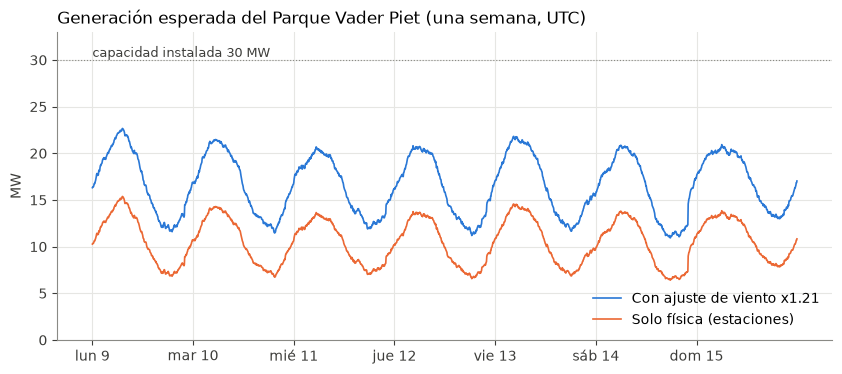

In [21]:
semana_p = parque.loc['2026-03-09':'2026-03-15']
fig, ax = plt.subplots()
ax.plot(semana_p.index, semana_p['wind_power_ajustada_kw'] / 1000, color=AZUL, linewidth=1.2, label=f'Con ajuste de viento x{ajuste_viento:.2f}')
ax.plot(semana_p.index, semana_p['wind_power_kw'] / 1000, color=NARANJA, linewidth=1.2, label='Solo física (estaciones)')
ax.axhline(capacidad_kw / 1000, color=GRIS, linewidth=0.8, linestyle=':')
ax.text(semana_p.index[0], capacidad_kw / 1000, 'capacidad instalada 30 MW', color='#3d3d3a', va='bottom', fontsize=9)
dias = pd.date_range('2026-03-09', periods=7, freq='D', tz='UTC')
ax.set_xticks(dias, [f"{n} {d.day}" for n, d in zip(['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom'], dias)])
ax.set(ylabel='MW', ylim=(0, 33))
ax.set_title('Generación esperada del Parque Vader Piet (una semana, UTC)', loc='left')
ax.legend(frameon=False, loc='lower right')
plt.show()

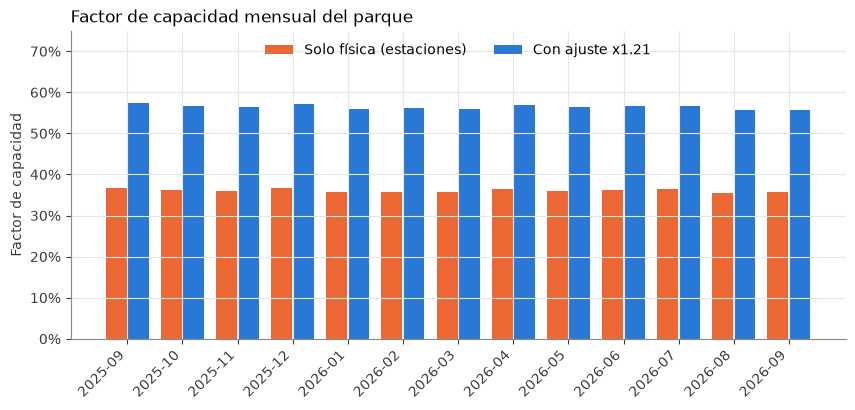

In [22]:
mensual = parque[['wind_power_kw', 'wind_power_ajustada_kw']].resample('MS').mean().div(capacidad_kw)
fig, ax = plt.subplots()
x = np.arange(len(mensual))
ax.bar(x - 0.2, mensual['wind_power_kw'], width=0.38, color=NARANJA, label='Solo física (estaciones)')
ax.bar(x + 0.2, mensual['wind_power_ajustada_kw'], width=0.38, color=AZUL, label=f'Con ajuste x{ajuste_viento:.2f}')
ax.set_xticks(x, [d.strftime('%Y-%m') for d in mensual.index], rotation=45, ha='right')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set(ylabel='Factor de capacidad', ylim=(0, 0.75))
ax.set_title('Factor de capacidad mensual del parque', loc='left')
ax.legend(frameon=False, loc='upper center', ncol=2)
plt.show()

Columnas resultantes en `parque` (una fila por instante): `v_buje_ms`, `densidad`, `wind_power_kw` (solo física) y `wind_power_ajustada_kw` (calibrada al 14 %). Se pueden unir al DataFrame de lecturas por `timestamp` para que el notebook de umbrales de seguridad use la potencia real (`wind_power_kw`) en lugar de la velocidad del viento.